In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Licence: CC BY 4.0
56 files, 47.8 GB
Main drives with seat pressure: 176 | drivers: 39
Participant sheet columns: ['pid', 'Gender', 'Age', 'DE (year)', 'DE (distance)', 'Height', 'BMI', 'No MS', 'Glasses', 'AD experience', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14']

SEAT: 1.03 GB | delimiter ',' | 2049 columns
first: ['time', 'Seat_1', 'Seat_2', 'Seat_3', 'Seat_4', 'Seat_5']
last: ['Back_1019', 'Back_1020', 'Back_1021', 'Back_1022', 'Back_1023', 'Back_1024']
non-numeric columns: [] | time column: ['time']
pressure columns: 2048 | leading empty rows: 41 | NaN share in valid rows: 0.0000
distinct frames/s: all 11.0 | first half 7.8 | second half 11.0
values: min 0.000 max 200.000 | integer-valued: True


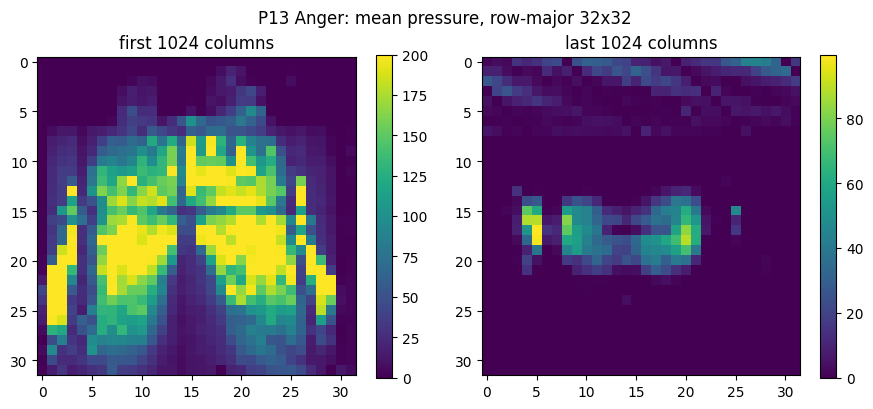


ZERO_TIME_VALUES: 7606 lines | head: ["('back', 0.0)", "('back', 0.00390625)", "('back', 0.0078125)", "('back', 0.01171875)"]

VEHICLE: 108826 rows | 12 columns: ['time', 'SteeringTorqueFeedback', 'LateralShift', 'TLC_Side', 'TLC_Time', 'Speed_Long', 'Acceleration_Long', 'TravelledDistance', 'IndicatorState', 'BackgroundMusic', 'InteractionSignal', 'AutomationMode']
  InteractionSignal: {7: 48422, 0: 36542, 14: 7693, 2: 6350, 6: 5120, 12: 4699}
  AutomationMode: {0.0: 83008, -1.0: 25396, 3.0: 257, 1.0: 127, nan: 38}
                mode  start  end
AutomationMode                  
1                NaN    0.0  0.0
2                NaN    0.0  0.0
3                NaN    0.0  0.0
4                NaN    0.0  0.0
5                NaN    0.0  0.0
6                NaN    0.0  0.0
7                NaN    0.0  0.0
8                NaN    0.0  0.0
9                NaN    0.0  0.0
10               NaN    0.0  0.0
11               NaN    0.0  0.0
12               NaN    0.0  0.0
13             

In [1]:
import re, time, shutil, subprocess, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

API, DOI = "https://dataverse.harvard.edu/api", "doi:10.7910/DVN/SG9TMD"
HDR = {"User-Agent": "Mozilla/5.0 (academic research download)"}
RAW, OUT = Path("/tmp/mand_raw"), Path("/kaggle/working/mand")
RAW.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
assert shutil.which("7z"), "7z not found: tell me and I will switch to py7zr"
t0 = time.time()

# 1. File list and licence
r = requests.get(f"{API}/datasets/:persistentId/", params={"persistentId": DOI}, headers=HDR, timeout=120)
r.raise_for_status()
v = r.json()["data"]["latestVersion"]
lic = v.get("license"); print("Licence:", lic.get("name") if isinstance(lic, dict) else lic)
FILES = pd.DataFrame([{"id": f["dataFile"]["id"], "name": f["dataFile"]["filename"],
                       "orig": f["dataFile"].get("originalFileName", f["dataFile"]["filename"]),
                       "MB": round(f["dataFile"]["filesize"] / 1e6, 1)} for f in v["files"]])
print(len(FILES), "files,", round(FILES.MB.sum() / 1e3, 1), "GB")

def fetch(row, dest):
    if dest.exists() and dest.stat().st_size > 0: return dest
    params = {"format": "original"} if row["orig"] != row["name"] else {}
    part = dest.with_name(dest.name + ".part")
    for k in range(4):
        try:
            with requests.get(f"{API}/access/datafile/{row['id']}", params=params, headers=HDR, stream=True, timeout=600) as rr:
                rr.raise_for_status()
                with open(part, "wb") as fh:
                    for ch in rr.iter_content(1 << 22): fh.write(ch)
            part.rename(dest); return dest
        except Exception as e:
            print(f"  retry {k + 1} {dest.name}: {e}"); time.sleep(15 * (k + 1))
    raise RuntimeError(f"Download failed: {dest.name}")

# 2. Metadata sheets
META = {}
for key in ["AvailableData", "ParticipantsCharacteristics", "DataInfoSheet"]:
    m = FILES[FILES.orig.str.contains(key, case=False)]
    assert len(m) == 1, f"{key}: {len(m)} matches\n{FILES.to_string()}"
    META[key] = fetch(m.iloc[0], OUT / m.iloc[0]["orig"])

av = pd.read_excel(META["AvailableData"], sheet_name="AvailableSensorData", header=None)
scen, sens, body = av.iloc[1].ffill(), av.iloc[2], av.iloc[3:53]
recs = [dict(pid=int(body.loc[i, 1]), scenario=scen[c], sensor=sens[c], ok=body.loc[i, c])
        for c in range(2, 44) for i in body.index]
A = pd.DataFrame(recs).pivot_table(index=["pid", "scenario"], columns="sensor", values="ok", aggfunc="first").reset_index()
PC = pd.read_excel(META["ParticipantsCharacteristics"]).rename(columns={"No.": "pid"})
A = A.merge(PC[["pid", "No MS"]], on="pid")
DRIVES = A[(A["No MS"] == 1) & (A.scenario != "Familiarization") & (A["BodiTrak"].fillna(0) == 1)][["pid", "scenario"]].reset_index(drop=True)
print("Main drives with seat pressure:", len(DRIVES), "| drivers:", DRIVES.pid.nunique())
print("Participant sheet columns:", list(PC.columns))

# 3. One driver's archive, then one drive inside it
PID, SCEN = 13, "Anger"
m = FILES[FILES.orig.str.fullmatch(rf"P0*{PID}\.(7z|zip)", case=False)]
assert len(m) == 1, f"P{PID} archive matches: {len(m)}\nNames: {sorted(FILES.orig)[:80]}"
arc = fetch(m.iloc[0], RAW / m.iloc[0]["orig"])
xdir = RAW / f"x{PID}"
subprocess.run(["7z", "x", "-y", f"-o{xdir}", str(arc)], check=True, capture_output=True)
inner = list(xdir.rglob(f"{SCEN}.7z")); assert len(inner) == 1, f"inner archives found: {inner}"
want = [f"{SCEN}/DriverState/SeatPressureSensor/SeatPressureDistribution.txt",
        f"{SCEN}/DriverState/SeatPressureSensor/Media/zero_time_values.txt",
        f"{SCEN}/VehicleState/Vehicle.txt"]
ddir = xdir / "drive"
subprocess.run(["7z", "x", "-y", f"-o{ddir}", str(inner[0])] + want, check=True, capture_output=True)
D = ddir / SCEN

def sniff(p):
    with open(p, errors="replace") as fh: h = fh.readline().rstrip("\n")
    return max(["\t", ",", ";"], key=h.count), h

# 4. Seat file layout
sp = D / "DriverState/SeatPressureSensor/SeatPressureDistribution.txt"
dl, h = sniff(sp); cols = h.split(dl)
print(f"\nSEAT: {sp.stat().st_size / 1e9:.2f} GB | delimiter {dl!r} | {len(cols)} columns")
print("first:", cols[:6]); print("last:", cols[-6:])
S = pd.read_csv(sp, sep=dl, nrows=30000)
nonnum = [c for c in S.columns if not pd.api.types.is_numeric_dtype(S[c])]
tcol = [c for c in S.columns if c.strip().lower() == "time"]
pcols = [c for c in S.columns if c not in tcol and c not in nonnum]
print("non-numeric columns:", nonnum[:10], "| time column:", tcol)
P = S[pcols].to_numpy(np.float32)
T = S[tcol[0]].to_numpy(float) if tcol else np.arange(len(S)) / 256
ok = ~np.isnan(P).all(1)
assert ok.sum() > 1000, "First 30k rows are empty: tell me and I will widen the probe"
Pv, Tv = np.nan_to_num(P[ok]), T[ok]
span = Tv[-1] - Tv[0]
rate = lambda X: np.r_[True, np.any(X[1:] != X[:-1], axis=1)].sum() / span
half = len(pcols) // 2
print(f"pressure columns: {len(pcols)} | leading empty rows: {int(np.argmax(ok))} | NaN share in valid rows: {np.isnan(P[ok]).mean():.4f}")
print(f"distinct frames/s: all {rate(Pv):.1f} | first half {rate(Pv[:, :half]):.1f} | second half {rate(Pv[:, half:]):.1f}")
print(f"values: min {Pv.min():.3f} max {Pv.max():.3f} | integer-valued: {bool(np.all(Pv == np.round(Pv)))}")
if len(pcols) == 2048:
    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    for a, X, nm in [(ax[0], Pv[:, :1024], "first 1024 columns"), (ax[1], Pv[:, 1024:], "last 1024 columns")]:
        im = a.imshow(X.mean(0).reshape(32, 32), cmap="viridis"); a.set_title(nm); plt.colorbar(im, ax=a)
    plt.suptitle(f"P{PID} {SCEN}: mean pressure, row-major 32x32"); plt.tight_layout(); plt.show()

# 5. Copied-frame log and vehicle log
z = (D / "DriverState/SeatPressureSensor/Media/zero_time_values.txt").read_text(errors="replace").splitlines()
print(f"\nZERO_TIME_VALUES: {len(z)} lines | head: {z[:4]}")
vp = D / "VehicleState/Vehicle.txt"; dl2, _ = sniff(vp)
V = pd.read_csv(vp, sep=dl2)
print(f"\nVEHICLE: {len(V)} rows | {len(V.columns)} columns: {list(V.columns)[:40]}")
for c in [c for c in V.columns if re.search("automation|interaction|takeover", c, re.I)]:
    print(f"  {c}: {V[c].value_counts(dropna=False).head(8).to_dict()}")
if {"time", "AutomationMode"} <= set(V.columns):
    seg = (V.AutomationMode != V.AutomationMode.shift()).cumsum()
    print(V.groupby(seg).agg(mode=("AutomationMode", "first"), start=("time", "first"), end=("time", "last")).round(1).head(30).to_string())

shutil.rmtree(xdir)
print(f"\nDone in {(time.time() - t0) / 60:.1f} min | /tmp free: {shutil.disk_usage('/tmp').free / 1e9:.0f} GB")

In [2]:
import gc, json, pyarrow as pa, pyarrow.csv as pacsv

# A. Official definitions of the codes we need
info = pd.read_excel(META["DataInfoSheet"], sheet_name=None, header=None)
pat = "AutomationMode|InteractionSignal|zero_time|SeatPressure|BodiTrak"
for sh, df in info.items():
    hit = df.astype(str).apply(lambda c: c.str.contains(pat, case=False, regex=True)).any(axis=1)
    for _, row in df[hit].iterrows():
        print(f"[{sh}]", " | ".join(str(x) for x in row.dropna().tolist())[:700])

# B. Build: seat + backrest on a fixed 8 Hz sample-and-hold grid, uint8, with blank-frame flags and vehicle codes
HZ = 8
CACHE = OUT / "cache"; CACHE.mkdir(exist_ok=True)
MAN = OUT / "manifest.csv"
VCOLS = ["AutomationMode", "InteractionSignal", "Speed_Long"]
NEED = ["SeatPressureDistribution.txt", "zero_time_values.txt", "Vehicle.txt"]
ZRE = re.compile(r"\('(\w+)',\s*([-0-9.eE+]+)\)")
norm = lambda s: re.sub(r"[^a-z]", "", str(s).lower())

def build_drive(files, pid, scen):
    tbl = pacsv.read_csv(files["SeatPressureDistribution.txt"])
    head = tbl.select(["time", "Seat_1", "Back_1"]).to_pandas()
    tt = head["time"].to_numpy(float)
    assert np.all(np.diff(tt) > 0), "seat time not strictly increasing"
    start = int(max(head.Seat_1.notna().to_numpy().argmax(), head.Back_1.notna().to_numpy().argmax()))
    g = np.arange(np.ceil(tt[start] * HZ) / HZ, tt[-1], 1 / HZ)
    idx = np.searchsorted(tt, g + 1e-9, side="right") - 1
    X = tbl.take(pa.array(idx)).to_pandas(); del tbl; gc.collect()
    seat = X[[f"Seat_{i}" for i in range(1, 1025)]].to_numpy()
    back = X[[f"Back_{i}" for i in range(1, 1025)]].to_numpy(); del X
    assert not np.isnan(seat).any() and not np.isnan(back).any(), "NaN after start row"
    assert min(seat.min(), back.min()) >= 0 and max(seat.max(), back.max()) <= 255, "values outside uint8"
    seat = seat.astype(np.uint8).reshape(-1, 32, 32); back = back.astype(np.uint8).reshape(-1, 32, 32)

    zk = {}
    for mat, t in ZRE.findall(files["zero_time_values.txt"].read_text(errors="replace")):
        zk.setdefault(mat, []).append(round(float(t) * 256))
    rk = np.round(tt[idx] * 256).astype(np.int64)
    seat_blank, back_blank = np.isin(rk, zk.get("seat", [])), np.isin(rk, zk.get("back", []))

    V = pd.read_csv(files["Vehicle.txt"], usecols=["time"] + VCOLS)
    vt = V.time.to_numpy(float); assert np.all(np.diff(vt) >= 0), "vehicle time not sorted"
    vi = np.searchsorted(vt, g + 1e-9, side="right") - 1
    veh = {c: np.where(vi >= 0, V[c].to_numpy(float)[np.clip(vi, 0, None)], np.nan).astype(np.float32) for c in VCOLS}

    np.savez_compressed(CACHE / f"P{pid:02d}_{norm(scen)}.npz", t=g.astype(np.float32), seat=seat, back=back,
                        seat_blank=seat_blank, back_blank=back_blank, **veh)
    bz = (back[back_blank].reshape(-1, 1024).sum(1) == 0).mean() if back_blank.any() else np.nan
    return dict(pid=pid, scenario=scen, frames=len(g), minutes=round(len(g) / HZ / 60, 1),
                seat_change=round(float(np.r_[True, np.any(seat[1:] != seat[:-1], axis=(1, 2))].mean()), 3),
                seat_sat=round(float((seat == 200).mean()), 4), seat_blank=round(float(seat_blank.mean()), 4),
                back_blank=round(float(back_blank.mean()), 4), back_blank_allzero=round(float(bz), 3),
                auto_codes=json.dumps({str(k): int(v) for k, v in pd.Series(veh["AutomationMode"]).value_counts(dropna=False).items()}),
                status="ok")

rows = [r for r in pd.read_csv(MAN).to_dict("records") if r.get("status") == "ok"] if MAN.exists() else []
done = {(int(r["pid"]), r["scenario"]) for r in rows}
t0, n_drivers = time.time(), DRIVES.pid.nunique()
for k, (pid, grp) in enumerate(DRIVES.groupby("pid")):
    todo = [s for s in grp.scenario if (int(pid), s) not in done]
    if not todo: continue
    xdir = RAW / f"x{pid}"
    try:
        m = FILES[FILES.orig.str.fullmatch(rf"P0*{pid}\.(7z|zip)", case=False)]
        assert len(m) == 1, f"{len(m)} archive matches"
        arc = fetch(m.iloc[0], RAW / m.iloc[0]["orig"])
        shutil.rmtree(xdir, ignore_errors=True)
        subprocess.run(["7z", "x", "-y", f"-o{xdir}", str(arc)], check=True, capture_output=True)
        inners = {norm(p.stem): p for p in xdir.rglob("*.7z")}
    except Exception as e:
        rows += [dict(pid=pid, scenario=s, status=f"archive error: {type(e).__name__}: {e}"[:200]) for s in todo]
        continue
    for s in todo:
        ddir = xdir / f"d_{norm(s)}"
        try:
            inner = inners.get(norm(s)); assert inner is not None, f"no inner archive; have {sorted(inners)}"
            subprocess.run(["7z", "x", "-y", f"-o{ddir}", str(inner)] + NEED + ["-r"], check=True, capture_output=True)
            files = {}
            for fn in NEED:
                hits = list(ddir.rglob(fn)); assert len(hits) == 1, f"{fn}: {len(hits)} found"; files[fn] = hits[0]
            rec = build_drive(files, int(pid), s)
        except Exception as e:
            rec = dict(pid=pid, scenario=s, status=f"error: {type(e).__name__}: {e}"[:200])
        rows.append(rec); shutil.rmtree(ddir, ignore_errors=True); gc.collect()
    shutil.rmtree(xdir, ignore_errors=True)
    pd.DataFrame(rows).to_csv(MAN, index=False)
    print(f"[{k + 1}/{n_drivers}] P{pid}: {sum(r['status'] == 'ok' for r in rows)} drives ok so far | {(time.time() - t0) / 60:.0f} min", flush=True)
    if not any(r["status"] == "ok" for r in rows):
        raise RuntimeError("First driver failed, stopping early:\n" + pd.DataFrame(rows).to_string())

M = pd.DataFrame(rows); M.to_csv(MAN, index=False)
ok = M[M.status == "ok"]
print(f"\nOK drives: {len(ok)} of {len(DRIVES)} | drivers: {ok.pid.nunique()} | {(time.time() - t0) / 60:.0f} min")
print("Failures:\n", M[M.status != "ok"][["pid", "scenario", "status"]].to_string(index=False))
print(ok.describe().round(3).to_string())
codes = pd.DataFrame([json.loads(c) for c in ok.auto_codes]).fillna(0).sum().astype(int)
print("AutomationMode codes, frames across all drives:", codes.to_dict())
print(ok[["pid", "scenario", "minutes", "seat_change", "seat_sat", "back_blank", "back_blank_allzero", "auto_codes"]].head(10).to_string(index=False))
print("Cache size:", round(sum(f.stat().st_size for f in CACHE.glob("*.npz")) / 1e9, 2), "GB")

[Vehicle] AutomationMode |    0
+1
-1
   2
   3 | Manual mode
Adaptive cruise control
Lane keeping
Automated Level 2
Automated level 3
[Vehicle] InteractionSignal | Interaction signal initiated by the vehicle/automated system:

[1/39] P1: 2 drives ok so far | 1 min
[2/39] P2: 5 drives ok so far | 3 min
[3/39] P3: 8 drives ok so far | 4 min
[4/39] P5: 12 drives ok so far | 6 min
[5/39] P6: 16 drives ok so far | 8 min
[6/39] P9: 20 drives ok so far | 11 min
[7/39] P10: 23 drives ok so far | 13 min
[8/39] P11: 27 drives ok so far | 15 min
[9/39] P12: 31 drives ok so far | 17 min
[10/39] P13: 36 drives ok so far | 19 min
[11/39] P14: 41 drives ok so far | 21 min
[12/39] P15: 46 drives ok so far | 23 min
[13/39] P16: 51 drives ok so far | 26 min
[14/39] P17: 56 drives ok so far | 28 min
[15/39] P19: 61 drives ok so far | 29 min
[16/39] P20: 66 drives ok so far | 32 min
[17/39] P21: 69 drives ok so far | 33 min
[18/39] P22: 74 drives ok so far | 36 min
[19/39] P23: 79 drives ok so far | 38 m

In [3]:
# Cell 3: retry failed drives; recording gaps are flagged instead of rejected, copied-frame log is optional
def build_drive(files, pid, scen):
    tbl = pacsv.read_csv(files["SeatPressureDistribution.txt"])
    head = tbl.select(["time", "Seat_1", "Back_1"]).to_pandas()
    tt = head["time"].to_numpy(float)
    assert np.all(np.diff(tt) > 0), "seat time not strictly increasing"
    start = int(max(head.Seat_1.notna().to_numpy().argmax(), head.Back_1.notna().to_numpy().argmax()))
    g = np.arange(np.ceil(tt[start] * HZ) / HZ, tt[-1], 1 / HZ)
    idx = np.searchsorted(tt, g + 1e-9, side="right") - 1
    X = tbl.take(pa.array(idx)).to_pandas(); del tbl; gc.collect()
    seat = X[[f"Seat_{i}" for i in range(1, 1025)]].to_numpy(float)
    back = X[[f"Back_{i}" for i in range(1, 1025)]].to_numpy(float); del X
    seat_gap, back_gap = np.isnan(seat).any(1), np.isnan(back).any(1)
    seat, back = np.nan_to_num(seat), np.nan_to_num(back)
    assert min(seat.min(), back.min()) >= 0 and max(seat.max(), back.max()) <= 255, "values outside uint8"
    seat = seat.astype(np.uint8).reshape(-1, 32, 32); back = back.astype(np.uint8).reshape(-1, 32, 32)

    zp, zk = files.get("zero_time_values.txt"), {}
    if zp is not None:
        for mat, t in ZRE.findall(zp.read_text(errors="replace")):
            zk.setdefault(mat, []).append(round(float(t) * 256))
    rk = np.round(tt[idx] * 256).astype(np.int64)
    seat_blank, back_blank = np.isin(rk, zk.get("seat", [])), np.isin(rk, zk.get("back", []))

    V = pd.read_csv(files["Vehicle.txt"], usecols=["time"] + VCOLS)
    vt = V.time.to_numpy(float); assert np.all(np.diff(vt) >= 0), "vehicle time not sorted"
    vi = np.searchsorted(vt, g + 1e-9, side="right") - 1
    veh = {c: np.where(vi >= 0, V[c].to_numpy(float)[np.clip(vi, 0, None)], np.nan).astype(np.float32) for c in VCOLS}

    np.savez_compressed(CACHE / f"P{pid:02d}_{norm(scen)}.npz", t=g.astype(np.float32), seat=seat, back=back,
                        seat_blank=seat_blank, back_blank=back_blank, seat_gap=seat_gap, back_gap=back_gap, **veh)
    bz = (back[back_blank].reshape(-1, 1024).sum(1) == 0).mean() if back_blank.any() else np.nan
    return dict(pid=pid, scenario=scen, frames=len(g), minutes=round(len(g) / HZ / 60, 1),
                seat_change=round(float(np.r_[True, np.any(seat[1:] != seat[:-1], axis=(1, 2))].mean()), 3),
                seat_sat=round(float((seat == 200).mean()), 4), seat_blank=round(float(seat_blank.mean()), 4),
                back_blank=round(float(back_blank.mean()), 4), back_blank_allzero=round(float(bz), 3),
                seat_gap=round(float(seat_gap.mean()), 4), back_gap=round(float(back_gap.mean()), 4), zero_log=zp is not None,
                auto_codes=json.dumps({str(k): int(v) for k, v in pd.Series(veh["AutomationMode"]).value_counts(dropna=False).items()}),
                status="ok")

rows = [r for r in pd.read_csv(MAN).to_dict("records") if r.get("status") == "ok"]
done = {(int(r["pid"]), r["scenario"]) for r in rows}
retry = DRIVES[[(int(p), s) not in done for p, s in zip(DRIVES.pid, DRIVES.scenario)]]
print("Retrying", len(retry), "drives from drivers", sorted(set(int(p) for p in retry.pid)))
t0 = time.time()
for pid, grp in retry.groupby("pid"):
    xdir = RAW / f"x{pid}"
    try:
        m = FILES[FILES.orig.str.fullmatch(rf"P0*{pid}\.(7z|zip)", case=False)]
        assert len(m) == 1, f"{len(m)} archive matches"
        arc = fetch(m.iloc[0], RAW / m.iloc[0]["orig"])
        shutil.rmtree(xdir, ignore_errors=True)
        subprocess.run(["7z", "x", "-y", f"-o{xdir}", str(arc)], check=True, capture_output=True)
        inners = {norm(p.stem): p for p in xdir.rglob("*.7z")}
    except Exception as e:
        rows += [dict(pid=pid, scenario=s, status=f"archive error: {type(e).__name__}: {e}"[:200]) for s in grp.scenario]
        continue
    for s in grp.scenario:
        ddir = xdir / f"d_{norm(s)}"
        try:
            inner = inners.get(norm(s)); assert inner is not None, f"no inner archive; have {sorted(inners)}"
            subprocess.run(["7z", "x", "-y", f"-o{ddir}", str(inner)] + NEED + ["-r"], check=True, capture_output=True)
            files = {}
            for fn in NEED:
                hits = list(ddir.rglob(fn))
                if fn == "zero_time_values.txt" and not hits: continue
                assert len(hits) == 1, f"{fn}: {len(hits)} found"; files[fn] = hits[0]
            rec = build_drive(files, int(pid), s)
        except Exception as e:
            rec = dict(pid=pid, scenario=s, status=f"error: {type(e).__name__}: {e}"[:200])
        rows.append(rec); shutil.rmtree(ddir, ignore_errors=True); gc.collect()
    shutil.rmtree(xdir, ignore_errors=True)
    print(f"P{pid} done | {(time.time() - t0) / 60:.1f} min", flush=True)

M = pd.DataFrame(rows); M.to_csv(MAN, index=False)
ok = M[M.status == "ok"]
print(f"\nOK drives: {len(ok)} of {len(DRIVES)} | drivers: {ok.pid.nunique()} | cache files: {len(list(CACHE.glob('*.npz')))}")
print("Still failing:\n", M[M.status != "ok"][["pid", "scenario", "status"]].to_string(index=False))
newly = ok[[(int(p), s) not in done for p, s in zip(ok.pid, ok.scenario)]]
print("\nRetried drives:")
print(newly[["pid", "scenario", "minutes", "seat_sat", "back_blank", "seat_gap", "back_gap", "zero_log", "auto_codes"]].to_string(index=False))

Retrying 13 drives from drivers [21, 24, 33, 48, 50]
P21 done | 0.3 min
P24 done | 0.7 min
P33 done | 1.2 min
P48 done | 3.4 min
P50 done | 5.3 min

OK drives: 176 of 176 | drivers: 39 | cache files: 176
Still failing:
 Empty DataFrame
Columns: [pid, scenario, status]
Index: []

Retried drives:
 pid   scenario  minutes  seat_sat  back_blank  seat_gap  back_gap zero_log                                                              auto_codes
  21 No Emotion      4.4    0.1186      0.0461       0.0    0.0005     True                          {"0.0": 2035, "-1.0": 63, "1.0": 29, "nan": 1}
  24    Sadness      5.4    0.0683      0.0869       0.0    0.0004     True              {"0.0": 2252, "3.0": 261, "-1.0": 41, "1.0": 32, "nan": 2}
  33    Sadness      8.9    0.4266      0.0336       0.0    0.0002     True             {"0.0": 2070, "2.0": 1334, "3.0": 864, "1.0": 12, "nan": 2}
  48      Anger      9.8    0.2843      0.0000       0.0    0.0000    False            {"3.0": 1937, "0.0": 1815

Drives: 176 | drivers: 39
Windows: 7558 | per driver min/median: 79/198 | drives per driver min: 2
Task labels (0 manual, 1 automated, -1 mixed/other): {1: 3794, 0: 2892, -1: 872}
E1       summary (24): window acc 0.843 [0.792, 0.888] | held-out drive identified 0.898 of 176
E1          map (128): window acc 0.981 [0.970, 0.990] | held-out drive identified 0.989 of 176
E1  summary+map (152): window acc 0.982 [0.969, 0.992] | held-out drive identified 1.000 of 176
Chance: 0.026
E1 permutation (drive-level label shuffle, 100): null mean 0.026, max 0.056 | p = 0.0099
E2 Height: R2 0.235 | MAE 0.05 vs mean-only 0.06 | permutation p = 0.0099
E2 BMI: R2 0.881 | MAE 1.54 vs mean-only 4.30 | permutation p = 0.0099
Seat saturation vs Height: Spearman rho 0.47 (p = 0.0024)
Seat saturation vs BMI: Spearman rho 0.62 (p = 0.0000)


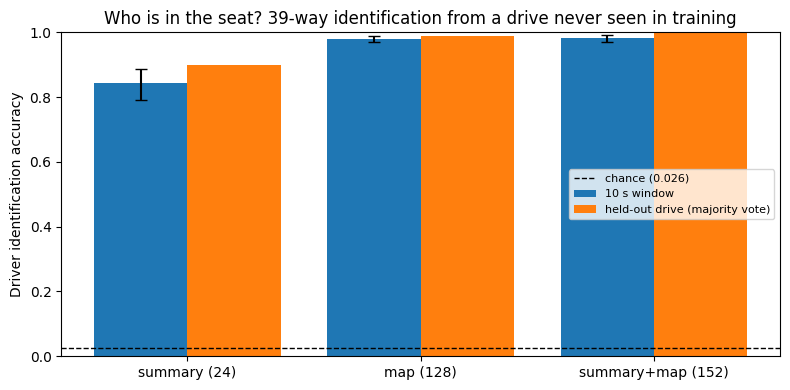

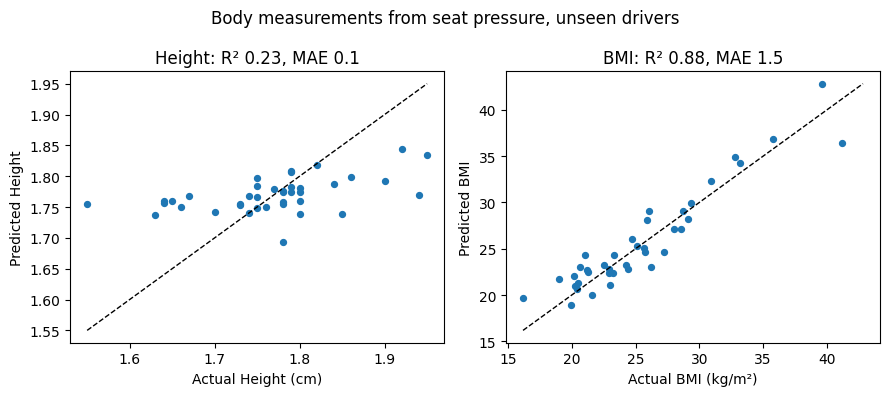

Done in 16.7 min


In [4]:
import json, re, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from joblib import Parallel, delayed
from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

OUT = Path("/kaggle/working/mand"); CACHE = OUT / "cache"; RES = OUT / "results"; RES.mkdir(exist_ok=True)
norm = lambda s: re.sub(r"[^a-z]", "", str(s).lower())
WIN, HZ = 80, 8
t_start = time.time()
M = pd.read_csv(OUT / "manifest.csv"); M = M[M.status == "ok"].copy()
PC = pd.read_excel(next(OUT.glob("ParticipantsCharacteristics*"))).rename(columns={"No.": "pid"}).set_index("pid")
print(f"Drives: {len(M)} | drivers: {M.pid.nunique()}")

# 1. Per-frame features
YY, XX = np.mgrid[0:32, 0:32].astype(np.float32)
def frame_feats(p):
    tot = p.sum((1, 2)); pos = tot > 0; safe = np.where(pos, tot, 1.0)
    cx = np.where(pos, (p * XX).sum((1, 2)) / safe, 15.5)
    cy = np.where(pos, (p * YY).sum((1, 2)) / safe, 15.5)
    left = p[:, :, :16].sum((1, 2))
    return dict(tot=tot, cx=cx, cy=cy, asym=np.where(pos, (2 * left - tot) / safe, 0.0),
                contact=(p > 0).mean((1, 2)), sat=(p >= 200).mean((1, 2)),
                diff=np.r_[0.0, np.abs(np.diff(p, axis=0)).mean((1, 2))])
SUM_NAMES = ["load_mean", "load_std", "contact", "saturation", "cop_x", "cop_y", "sway_x", "sway_y",
             "path_per_s", "shift_rate", "micro_move", "lr_asym"]

# 2. Non-overlapping 10 s windows with at least 90% valid frames
recs, FEAT = [], []
for pid, grp in M.groupby("pid"):
    for di, scen in enumerate(sorted(grp.scenario)):
        z = np.load(CACHE / f"P{int(pid):02d}_{norm(scen)}.npz")
        seat, back = z["seat"].astype(np.float32), z["back"].astype(np.float32)
        bad = z["seat_blank"] | z["back_blank"]
        for k in ("seat_gap", "back_gap"):
            if k in z.files: bad = bad | z[k]
        valid, am, tt = ~bad, z["AutomationMode"], z["t"]
        F = [frame_feats(seat), frame_feats(back)]
        for w in range(len(tt) // WIN):
            s = slice(w * WIN, (w + 1) * WIN); v = valid[s]
            if v.mean() < 0.9: continue
            pair = v[1:] & v[:-1]; row = []
            for f in F:
                cxv, cyv = f["cx"][s][v], f["cy"][s][v]
                step = np.hypot(np.diff(f["cx"][s]), np.diff(f["cy"][s]))[pair]
                d = f["diff"][s][1:][pair]
                row += [f["tot"][s][v].mean(), f["tot"][s][v].std(), f["contact"][s][v].mean(), f["sat"][s][v].mean(),
                        cxv.mean(), cyv.mean(), cxv.std(), cyv.std(), step.sum() / (WIN / HZ),
                        (step > 0.5).mean() if step.size else 0.0, d.mean() if d.size else 0.0, f["asym"][s][v].mean()]
            for mat in (seat, back):
                row += list(mat[s][v].mean(0).reshape(8, 4, 8, 4).mean((1, 3)).ravel())
            a = am[s][v]; man, aut = (a == 0).mean(), np.isin(a, [2, 3]).mean()
            FEAT.append(row)
            recs.append(dict(pid=int(pid), scenario=scen, drive=f"{int(pid)}_{norm(scen)}", fold=di, t0=float(tt[s][0]),
                             label=0 if man >= 0.9 else (1 if aut >= 0.9 else -1)))

W = pd.DataFrame(recs)
cols = ([f"seat_{n}" for n in SUM_NAMES] + [f"back_{n}" for n in SUM_NAMES]
        + [f"seat_map{i}" for i in range(64)] + [f"back_map{i}" for i in range(64)])
X = pd.DataFrame(np.asarray(FEAT, np.float32), columns=cols)
assert len(X) == len(W) and np.isfinite(X.to_numpy()).all(), "non-finite features"
W.to_parquet(RES / "windows.parquet"); X.to_parquet(RES / "features.parquet")
nd = W.groupby("pid").drive.nunique()
print(f"Windows: {len(W)} | per driver min/median: {W.pid.value_counts().min()}/{int(W.pid.value_counts().median())} "
      f"| drives per driver min: {nd.min()}")
print("Task labels (0 manual, 1 automated, -1 mixed/other):", W.label.value_counts().to_dict())
assert nd.min() >= 2, f"drivers with one drive: {nd[nd < 2].index.tolist()}"

# 3. E1: 39-way identity from a held-out drive (folds by drive index)
y, fold, DID = W.pid.to_numpy(), W.fold.to_numpy(), W.drive.to_numpy()
drive_pid = W.groupby("drive").pid.first()
def fit_predict(Xa, ylab, tr, te):
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, tol=1e-3))
    clf.fit(Xa[tr], ylab[tr]); return clf.predict(Xa[te])
def run_id(Xa, ylab):
    pred = np.zeros_like(y)
    for f in np.unique(fold):
        tr, te = fold != f, fold == f
        pred[te] = fit_predict(Xa, ylab, tr, te)
    return pred
def boot_ci(correct, groups, B=1000, seed=0):
    rng = np.random.default_rng(seed)
    s = pd.DataFrame({"c": correct.astype(float), "g": groups}).groupby("g").c.agg(["sum", "count"]).to_numpy()
    idx = rng.integers(0, len(s), (B, len(s)))
    return np.percentile(s[idx, 0].sum(1) / s[idx, 1].sum(1), [2.5, 97.5])
def drive_vote(pred):
    d = pd.DataFrame({"drive": DID, "y": y, "p": pred}).groupby("drive").agg(y=("y", "first"), p=("p", lambda q: q.mode().iloc[0]))
    return float((d.y == d.p).mean()), len(d)

SETS = {"summary (24)": cols[:24], "map (128)": cols[24:], "summary+map (152)": cols}
E1 = {}
for name, cs in SETS.items():
    pred = run_id(X[cs].to_numpy(), y); corr = pred == y
    lo, hi = boot_ci(corr, y); dacc, ndr = drive_vote(pred)
    E1[name] = dict(window_acc=float(corr.mean()), ci=[float(lo), float(hi)], drive_acc=dacc, n_drives=ndr)
    print(f"E1 {name:>18}: window acc {corr.mean():.3f} [{lo:.3f}, {hi:.3f}] | held-out drive identified {dacc:.3f} of {ndr}")
chance = 1 / W.pid.nunique(); print(f"Chance: {chance:.3f}")

Xa = X[cols].to_numpy(); acc_full = E1["summary+map (152)"]["window_acc"]
def perm_once(seed):
    rng = np.random.default_rng(seed); pred = np.zeros_like(y)
    for f in np.unique(fold):
        tr, te = fold != f, fold == f
        dk = np.unique(DID[tr]); mp = dict(zip(dk, rng.permutation(drive_pid.loc[dk].to_numpy())))
        ylab = y.copy(); ylab[tr] = [mp[d] for d in DID[tr]]
        pred[te] = fit_predict(Xa, ylab, tr, te)
    return float((pred == y).mean())
null = np.array(Parallel(n_jobs=-1)(delayed(perm_once)(s) for s in range(100)))
p_e1 = (1 + (null >= acc_full).sum()) / 101
print(f"E1 permutation (drive-level label shuffle, 100): null mean {null.mean():.3f}, max {null.max():.3f} | p = {p_e1:.4f}")

# 4. E2: leave-one-driver-out height and BMI from drive-averaged features
D = pd.concat([W[["drive", "pid"]], X], axis=1).groupby("drive").agg({**{c: "mean" for c in cols}, "pid": "first"})
Xd, gd = D[cols].to_numpy(), D.pid.to_numpy()
def lodo_ridge(tgt):
    yd = np.array([tgt[p] for p in gd], float); pred, base = np.zeros(len(yd)), np.zeros(len(yd))
    for p in np.unique(gd):
        tr, te = gd != p, gd == p
        gs = GridSearchCV(make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": np.logspace(-1, 4, 11)},
                          cv=GroupKFold(5), scoring="neg_mean_absolute_error")
        gs.fit(Xd[tr], yd[tr], groups=gd[tr]); pred[te] = gs.predict(Xd[te]); base[te] = yd[tr].mean()
    r = pd.DataFrame({"pid": gd, "y": yd, "p": pred, "b": base}).groupby("pid").mean()
    return r2_score(r.y, r.p), mean_absolute_error(r.y, r.p), mean_absolute_error(r.y, r.b), r
def e2_perm(seed, tgt):
    rng = np.random.default_rng(seed); ks = list(tgt)
    return lodo_ridge(dict(zip(ks, rng.permutation([tgt[k] for k in ks]))))[0]
E2, E2r = {}, {}
for t in ["Height", "BMI"]:
    tgt = {int(p): float(PC.loc[p, t]) for p in np.unique(gd)}
    assert all(np.isfinite(list(tgt.values()))), f"missing {t}"
    r2, mae, mae_b, r = lodo_ridge(tgt); E2r[t] = r
    nl = np.array(Parallel(n_jobs=-1)(delayed(e2_perm)(s, tgt) for s in range(100)))
    p = (1 + (nl >= r2).sum()) / 101
    E2[t] = dict(r2=float(r2), mae=float(mae), mae_baseline=float(mae_b), p=float(p))
    print(f"E2 {t}: R2 {r2:.3f} | MAE {mae:.2f} vs mean-only {mae_b:.2f} | permutation p = {p:.4f}")
drv = D.groupby("pid")["seat_saturation"].mean()
for t in ["Height", "BMI"]:
    rho, pr = spearmanr(drv.to_numpy(), PC.loc[drv.index, t].to_numpy())
    E2[f"seat_saturation_vs_{t}"] = dict(rho=float(rho), p=float(pr))
    print(f"Seat saturation vs {t}: Spearman rho {rho:.2f} (p = {pr:.4f})")

# 5. Figures and saved results
FIG = OUT / "figures"; FIG.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 4)); names = list(E1); xi = np.arange(len(names))
wa = [E1[n]["window_acc"] for n in names]; err = np.array([[w - E1[n]["ci"][0], E1[n]["ci"][1] - w] for n, w in zip(names, wa)]).T
ax.bar(xi - 0.2, wa, 0.4, yerr=err, capsize=4, label="10 s window")
ax.bar(xi + 0.2, [E1[n]["drive_acc"] for n in names], 0.4, label="held-out drive (majority vote)")
ax.axhline(chance, ls="--", c="k", lw=1, label=f"chance ({chance:.3f})")
ax.set_xticks(xi); ax.set_xticklabels(names); ax.set_ylabel("Driver identification accuracy"); ax.set_ylim(0, 1)
ax.set_title(f"Who is in the seat? 39-way identification from a drive never seen in training"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "e1_identity.png", dpi=200); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, t, u in [(ax[0], "Height", "cm"), (ax[1], "BMI", "kg/m²")]:
    r = E2r[t]; a.scatter(r.y, r.p, s=18); lim = [min(r.y.min(), r.p.min()), max(r.y.max(), r.p.max())]
    a.plot(lim, lim, "k--", lw=1); a.set_xlabel(f"Actual {t} ({u})"); a.set_ylabel(f"Predicted {t}")
    a.set_title(f"{t}: R² {E2[t]['r2']:.2f}, MAE {E2[t]['mae']:.1f}")
plt.suptitle("Body measurements from seat pressure, unseen drivers"); plt.tight_layout(); plt.savefig(FIG / "e2_body.png", dpi=200); plt.show()
json.dump(dict(E1=E1, E1_perm_p=float(p_e1), chance=chance, E2=E2, n_windows=len(W), n_drives=len(D)),
          open(RES / "e1_e2.json", "w"), indent=2)
print(f"Done in {(time.time() - t_start) / 60:.1f} min")

Reference windows: 959 | evaluation windows: 6599 | labelled evaluation windows: 5763
        time+scenario only (HGB): k-fold AUROC 0.853 | LODO AUROC 0.852 [0.817, 0.886] | LODO bal. acc 0.795
  seat raw + time+scenario (HGB): k-fold AUROC 0.998 | LODO AUROC 0.843 [0.787, 0.895] | LODO bal. acc 0.762
                  seat raw (HGB): k-fold AUROC 0.997 | LODO AUROC 0.790 [0.729, 0.848] | LODO bal. acc 0.725

                             raw: identity 0.979 | k-fold AUROC 0.961 | LODO AUROC 0.753 [0.685, 0.822] | gap +0.208 | LODO bal. acc 0.695
                        relative: identity 0.984 | k-fold AUROC 0.954 | LODO AUROC 0.752 [0.675, 0.827] | gap +0.202 | LODO bal. acc 0.682
                drive-normalised: identity 0.549 | k-fold AUROC 0.962 | LODO AUROC 0.822 [0.776, 0.868] | gap +0.140 | LODO bal. acc 0.742
     relative + drive-normalised: identity 0.501 | k-fold AUROC 0.951 | LODO AUROC 0.809 [0.760, 0.858] | gap +0.142 | LODO bal. acc 0.749


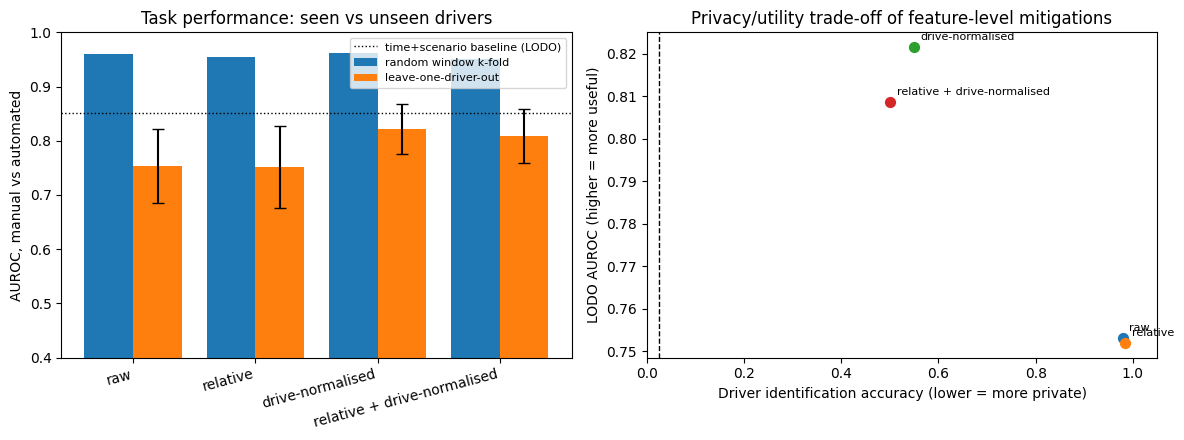

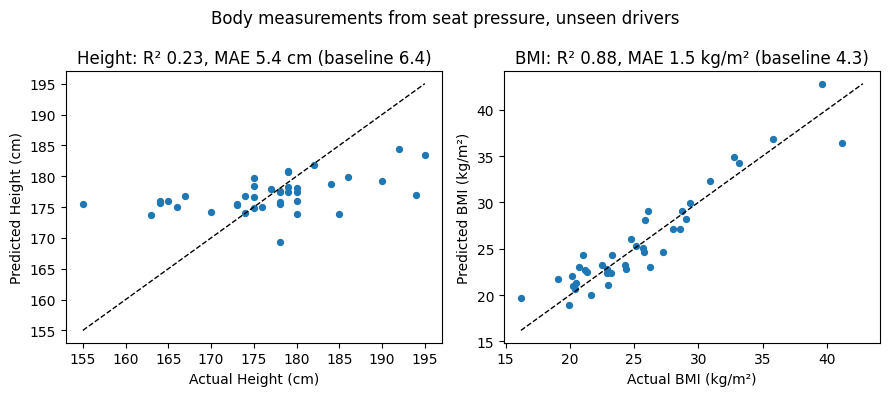


Done in 7.6 min


In [5]:
import json, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, balanced_accuracy_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

OUT = Path("/kaggle/working/mand"); RES, FIG = OUT / "results", OUT / "figures"
W = pd.read_parquet(RES / "windows.parquet"); X = pd.read_parquet(RES / "features.parquet")
cols = list(X.columns); SUMN = [c[5:] for c in cols[:12]]
t_start = time.time()

# Reference period: each drive's first 60 s of valid windows (used only by the normalisation variants)
ref = (W.t0 < W.groupby("drive").t0.transform("min") + 60).to_numpy()
EVAL = ~ref; LAB = W.label.to_numpy() >= 0
print(f"Reference windows: {ref.sum()} | evaluation windows: {EVAL.sum()} | labelled evaluation windows: {(EVAL & LAB).sum()}")

ABS = ["load_mean", "load_std", "saturation", "micro_move"]
def relative(Xdf):
    R = {}
    for mat in ("seat", "back"):
        for n in SUMN:
            if n not in ABS: R[f"{mat}_{n}"] = Xdf[f"{mat}_{n}"]
        R[f"{mat}_micro_rel"] = Xdf[f"{mat}_micro_move"] / (Xdf[f"{mat}_load_mean"] + 1.0)
        mp = Xdf[[f"{mat}_map{i}" for i in range(64)]]; s = mp.sum(1) + 1e-6
        for i in range(64): R[f"{mat}_rmap{i}"] = mp[f"{mat}_map{i}"] / s
    return pd.DataFrame(R)
def drive_norm(Xdf):
    refmean = Xdf[ref].groupby(W.drive[ref].to_numpy()).mean()
    return Xdf - refmean.loc[W.drive].to_numpy()

VARIANTS = {"raw": X, "relative": relative(X), "drive-normalised": drive_norm(X),
            "relative + drive-normalised": drive_norm(relative(X))}
for k, v in VARIANTS.items():
    assert np.isfinite(v.to_numpy()).all(), f"non-finite values in {k}"

LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, tol=1e-3))
HGB = lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=0)

def boot_auc(yl, q, g, B=1000, seed=0):
    rng = np.random.default_rng(seed); ug = np.unique(g); ix = {d: np.where(g == d)[0] for d in ug}; out = []
    for _ in range(B):
        ii = np.concatenate([ix[d] for d in rng.choice(ug, len(ug))])
        if len(np.unique(yl[ii])) == 2: out.append(roc_auc_score(yl[ii], q[ii]))
    return [float(v) for v in np.percentile(out, [2.5, 97.5])]

def task_eval(F, model):
    m = EVAL & LAB; Xa, yl, g = F[m], W.label.to_numpy()[m], W.pid.to_numpy()[m]
    p = np.zeros(len(yl))
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(Xa, yl):
        p[te] = model().fit(Xa[tr], yl[tr]).predict_proba(Xa[te])[:, 1]
    q = np.zeros(len(yl))
    for d in np.unique(g):
        tr, te = g != d, g == d
        q[te] = model().fit(Xa[tr], yl[tr]).predict_proba(Xa[te])[:, 1]
    return dict(kfold_auc=float(roc_auc_score(yl, p)), lodo_auc=float(roc_auc_score(yl, q)),
                lodo_ci=boot_auc(yl, q, g), lodo_bacc=float(balanced_accuracy_score(yl, q >= 0.5)))

def id_eval(F):
    Xa, y, fold = F[EVAL], W.pid.to_numpy()[EVAL], W.fold.to_numpy()[EVAL]
    pred = np.zeros_like(y)
    for f in np.unique(fold):
        tr, te = fold != f, fold == f
        pred[te] = LR().fit(Xa[tr], y[tr]).predict(Xa[te])
    return float((pred == y).mean())

# Baselines: time in drive and scenario only, and seat + time
ctx = pd.get_dummies(W.scenario).astype(float); ctx["t0"] = W.t0
E3 = {"time+scenario only (HGB)": task_eval(ctx.to_numpy(), HGB),
      "seat raw + time+scenario (HGB)": task_eval(pd.concat([X, ctx], axis=1).to_numpy(), HGB),
      "seat raw (HGB)": task_eval(X.to_numpy(), HGB)}
for k, r in E3.items():
    print(f"{k:>32}: k-fold AUROC {r['kfold_auc']:.3f} | LODO AUROC {r['lodo_auc']:.3f} "
          f"[{r['lodo_ci'][0]:.3f}, {r['lodo_ci'][1]:.3f}] | LODO bal. acc {r['lodo_bacc']:.3f}")

# Mitigations: identity leakage against task performance (linear models, as in E1)
print()
for k, F in VARIANTS.items():
    Fa = F.to_numpy(np.float64); r = task_eval(Fa, LR); r["identity_acc"] = id_eval(Fa); E3[k] = r
    print(f"{k:>32}: identity {r['identity_acc']:.3f} | k-fold AUROC {r['kfold_auc']:.3f} | LODO AUROC {r['lodo_auc']:.3f} "
          f"[{r['lodo_ci'][0]:.3f}, {r['lodo_ci'][1]:.3f}] | gap {r['kfold_auc'] - r['lodo_auc']:+.3f} | LODO bal. acc {r['lodo_bacc']:.3f}")

# Figure: k-fold vs LODO, and the privacy/utility trade-off
names = list(VARIANTS); xi = np.arange(len(names)); chance_id = 1 / W.pid.nunique()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(xi - 0.2, [E3[n]["kfold_auc"] for n in names], 0.4, label="random window k-fold")
lo = [E3[n]["lodo_auc"] - E3[n]["lodo_ci"][0] for n in names]; hi = [E3[n]["lodo_ci"][1] - E3[n]["lodo_auc"] for n in names]
ax[0].bar(xi + 0.2, [E3[n]["lodo_auc"] for n in names], 0.4, yerr=[lo, hi], capsize=4, label="leave-one-driver-out")
ax[0].axhline(E3["time+scenario only (HGB)"]["lodo_auc"], ls=":", c="k", lw=1, label="time+scenario baseline (LODO)")
ax[0].set_xticks(xi); ax[0].set_xticklabels(names, rotation=15, ha="right"); ax[0].set_ylim(0.4, 1.0)
ax[0].set_ylabel("AUROC, manual vs automated"); ax[0].set_title("Task performance: seen vs unseen drivers"); ax[0].legend(fontsize=8)
for n in names:
    ax[1].scatter(E3[n]["identity_acc"], E3[n]["lodo_auc"], s=50); ax[1].annotate(n, (E3[n]["identity_acc"], E3[n]["lodo_auc"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax[1].axvline(chance_id, ls="--", c="k", lw=1); ax[1].set_xlim(0, 1.05)
ax[1].set_xlabel("Driver identification accuracy (lower = more private)"); ax[1].set_ylabel("LODO AUROC (higher = more useful)")
ax[1].set_title("Privacy/utility trade-off of feature-level mitigations")
plt.tight_layout(); plt.savefig(FIG / "e3_confound.png", dpi=200); plt.show()

# Corrected E2 figure (height in cm), if Cell 4's results are still in memory
if "E2r" in globals():
    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    for a, t, u, sc in [(ax[0], "Height", "cm", 100), (ax[1], "BMI", "kg/m²", 1)]:
        r = E2r[t]; yy, pp = r.y * sc, r.p * sc; lim = [min(yy.min(), pp.min()), max(yy.max(), pp.max())]
        a.scatter(yy, pp, s=18); a.plot(lim, lim, "k--", lw=1)
        a.set_xlabel(f"Actual {t} ({u})"); a.set_ylabel(f"Predicted {t} ({u})")
        a.set_title(f"{t}: R² {E2[t]['r2']:.2f}, MAE {E2[t]['mae'] * sc:.1f} {u} (baseline {E2[t]['mae_baseline'] * sc:.1f})")
    plt.suptitle("Body measurements from seat pressure, unseen drivers"); plt.tight_layout()
    plt.savefig(FIG / "e2_body.png", dpi=200); plt.show()
else:
    print("E2 figure not redrawn: Cell 4 variables are gone. I will redraw it in the final figures cell.")

json.dump(E3, open(RES / "e3.json", "w"), indent=2)
print(f"\nDone in {(time.time() - t_start) / 60:.1f} min")

Windows: 7558 | features per resolution: [152, 152, 152, 56, 32]
Self-check, 32x32 reproduces Cell 4 features: True (max abs diff 2.94e-08)
32x32 (1024 taxels/mat)              raw: identity 0.979 | LODO AUROC 0.753 [0.685, 0.822]
32x32 (1024 taxels/mat) drive-normalised: identity 0.549 | LODO AUROC 0.822 [0.776, 0.868]
16x16 ( 256 taxels/mat)              raw: identity 0.979 | LODO AUROC 0.749 [0.677, 0.822]
16x16 ( 256 taxels/mat) drive-normalised: identity 0.550 | LODO AUROC 0.819 [0.766, 0.870]
 8x8  (  64 taxels/mat)              raw: identity 0.979 | LODO AUROC 0.743 [0.672, 0.817]
 8x8  (  64 taxels/mat) drive-normalised: identity 0.547 | LODO AUROC 0.819 [0.766, 0.870]
 4x4  (  16 taxels/mat)              raw: identity 0.958 | LODO AUROC 0.757 [0.690, 0.819]
 4x4  (  16 taxels/mat) drive-normalised: identity 0.398 | LODO AUROC 0.883 [0.851, 0.914]
 2x2  (   4 taxels/mat)              raw: identity 0.743 | LODO AUROC 0.767 [0.709, 0.827]
 2x2  (   4 taxels/mat) drive-normalised:

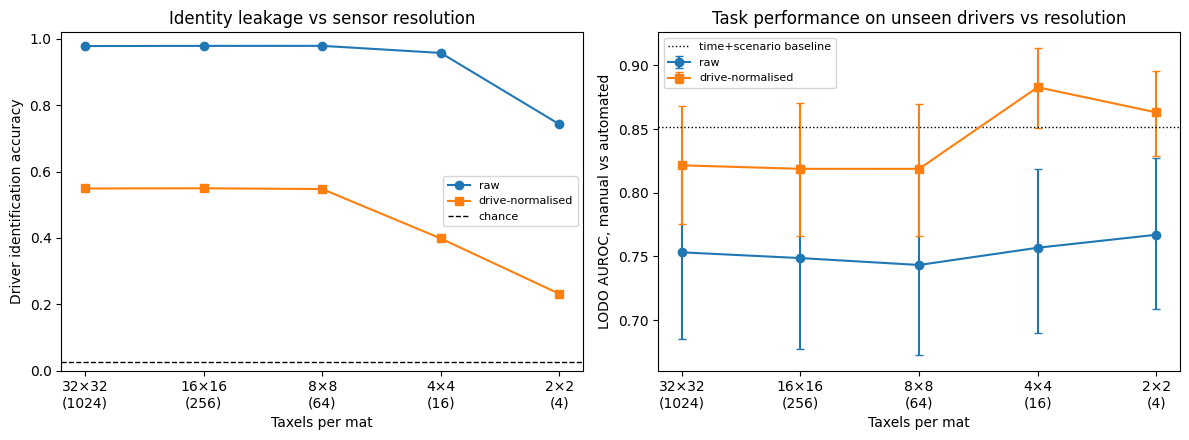

Done in 6.0 min


In [6]:
import json, re, time, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

OUT = Path("/kaggle/working/mand"); CACHE, RES, FIG = OUT / "cache", OUT / "results", OUT / "figures"
norm = lambda s: re.sub(r"[^a-z]", "", str(s).lower())
WIN, HZ, RESOL = 80, 8, [32, 16, 8, 4, 2]
W = pd.read_parquet(RES / "windows.parquet"); X0 = pd.read_parquet(RES / "features.parquet")
M = pd.read_csv(OUT / "manifest.csv"); M = M[M.status == "ok"]
t_start = time.time()

# 1. Features at each resolution (same windows and rules as Cell 4)
def frame_feats_r(p, r):
    b = 32 // r
    q = p if r == 32 else p.reshape(len(p), r, b, r, b).mean((2, 4))
    YY, XX = ((np.mgrid[0:r, 0:r] + 0.5) * b - 0.5).astype(np.float32)
    tot = q.sum((1, 2)); pos = tot > 0; safe = np.where(pos, tot, 1.0)
    cx = np.where(pos, (q * XX).sum((1, 2)) / safe, 15.5); cy = np.where(pos, (q * YY).sum((1, 2)) / safe, 15.5)
    left = q[:, :, :r // 2].sum((1, 2))
    return q, dict(tot=tot, cx=cx, cy=cy, asym=np.where(pos, (2 * left - tot) / safe, 0.0),
                   contact=(q > 0).mean((1, 2)), sat=(q >= 200).mean((1, 2)),
                   diff=np.r_[0.0, np.abs(np.diff(q, axis=0)).mean((1, 2))])
def win_map(q, s, v, r):
    m = q[s][v].mean(0)
    return (m.reshape(8, r // 8, 8, r // 8).mean((1, 3)) if r >= 8 else m).ravel()

FEAT = {r: [] for r in RESOL}; T0 = []
for pid, grp in M.groupby("pid"):
    for scen in sorted(grp.scenario):
        z = np.load(CACHE / f"P{int(pid):02d}_{norm(scen)}.npz")
        seat, back = z["seat"].astype(np.float32), z["back"].astype(np.float32)
        bad = z["seat_blank"] | z["back_blank"]
        for k in ("seat_gap", "back_gap"):
            if k in z.files: bad = bad | z[k]
        valid, tt = ~bad, z["t"]
        per_r = {r: [frame_feats_r(seat, r), frame_feats_r(back, r)] for r in RESOL}
        for w in range(len(tt) // WIN):
            s = slice(w * WIN, (w + 1) * WIN); v = valid[s]
            if v.mean() < 0.9: continue
            pair = v[1:] & v[:-1]; T0.append(float(tt[s][0]))
            for r in RESOL:
                row = []
                for q, f in per_r[r]:
                    cxv, cyv = f["cx"][s][v], f["cy"][s][v]
                    step = np.hypot(np.diff(f["cx"][s]), np.diff(f["cy"][s]))[pair]
                    d = f["diff"][s][1:][pair]
                    row += [f["tot"][s][v].mean(), f["tot"][s][v].std(), f["contact"][s][v].mean(), f["sat"][s][v].mean(),
                            cxv.mean(), cyv.mean(), cxv.std(), cyv.std(), step.sum() / (WIN / HZ),
                            (step > 0.5).mean() if step.size else 0.0, d.mean() if d.size else 0.0, f["asym"][s][v].mean()]
                for q, f in per_r[r]:
                    row += list(win_map(q, s, v, r))
                FEAT[r].append(row)
F = {r: np.asarray(FEAT[r], np.float64) for r in RESOL}
assert len(T0) == len(W) and np.allclose(T0, W.t0), "windows do not match Cell 4"
diff32 = np.abs(F[32] - X0.to_numpy(np.float64)).max()
print(f"Windows: {len(W)} | features per resolution: {[F[r].shape[1] for r in RESOL]}")
print(f"Self-check, 32x32 reproduces Cell 4 features: {diff32 < 1e-3} (max abs diff {diff32:.2e})")

# 2. Evaluation helpers (identical protocol to Cells 4 and 5)
ref = (W.t0 < W.groupby("drive").t0.transform("min") + 60).to_numpy(); EVAL = ~ref; LAB = W.label.to_numpy() >= 0
LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, tol=1e-3))
def drive_norm_np(Fa):
    df = pd.DataFrame(Fa); rm = df[ref].groupby(W.drive[ref].to_numpy()).mean()
    return (df - rm.loc[W.drive].to_numpy()).to_numpy()
def id_eval(Fa):
    Xa, y, fold = Fa[EVAL], W.pid.to_numpy()[EVAL], W.fold.to_numpy()[EVAL]; pred = np.zeros_like(y)
    for f in np.unique(fold):
        tr, te = fold != f, fold == f; pred[te] = LR().fit(Xa[tr], y[tr]).predict(Xa[te])
    return float((pred == y).mean())
def lodo_pred(Fa):
    m = EVAL & LAB; Xa, yl, g = Fa[m], W.label.to_numpy()[m], W.pid.to_numpy()[m]; q = np.zeros(len(yl))
    for d in np.unique(g):
        tr, te = g != d, g == d; q[te] = LR().fit(Xa[tr], yl[tr]).predict_proba(Xa[te])[:, 1]
    return yl, q, g
def boot_idx(g, rng):
    ug = np.unique(g); ix = {d: np.where(g == d)[0] for d in ug}
    return np.concatenate([ix[d] for d in rng.choice(ug, len(ug))])
def boot_auc(yl, q, g, B=1000, seed=0):
    rng = np.random.default_rng(seed); out = []
    for _ in range(B):
        ii = boot_idx(g, rng)
        if len(np.unique(yl[ii])) == 2: out.append(roc_auc_score(yl[ii], q[ii]))
    return [float(v) for v in np.percentile(out, [2.5, 97.5])]

# 3. E4 sweep
E4, preds = {}, {}
for r in RESOL:
    for var, Fv in [("raw", F[r]), ("drive-normalised", drive_norm_np(F[r]))]:
        assert np.isfinite(Fv).all(), f"non-finite features at {r} {var}"
        ida = id_eval(Fv); yl, q, g = lodo_pred(Fv); auc = float(roc_auc_score(yl, q)); ci = boot_auc(yl, q, g)
        E4[f"{r}x{r} | {var}"] = dict(res=r, taxels_per_mat=r * r, variant=var, identity_acc=ida, lodo_auc=auc, lodo_ci=ci)
        if r == 32: preds[var] = (yl, q, g)
        print(f"{r:>2}x{r:<2} ({r * r:>4} taxels/mat) {var:>16}: identity {ida:.3f} | LODO AUROC {auc:.3f} [{ci[0]:.3f}, {ci[1]:.3f}]", flush=True)
print("Self-check, Cell 5 at 32x32 raw: identity 0.979, LODO AUROC 0.753")

# 4. Paired driver-level bootstrap: does drive normalisation really improve unseen-driver AUROC?
yl, qa, g = preds["raw"]; _, qb, _ = preds["drive-normalised"]
rng = np.random.default_rng(1); dd = []
for _ in range(2000):
    ii = boot_idx(g, rng)
    if len(np.unique(yl[ii])) == 2: dd.append(roc_auc_score(yl[ii], qb[ii]) - roc_auc_score(yl[ii], qa[ii]))
dd = np.array(dd); obs = roc_auc_score(yl, qb) - roc_auc_score(yl, qa)
paired = dict(delta_auc=float(obs), ci=[float(v) for v in np.percentile(dd, [2.5, 97.5])], p_one_sided=float((dd <= 0).mean()))
print(f"\nPaired test, drive-normalised minus raw (LODO AUROC): {obs:+.3f} "
      f"[{paired['ci'][0]:+.3f}, {paired['ci'][1]:+.3f}] | one-sided bootstrap p = {paired['p_one_sided']:.4f}")

# 5. Figure
base = json.load(open(RES / "e3.json"))["time+scenario only (HGB)"]["lodo_auc"]; chance = 1 / W.pid.nunique()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); tx = [r * r for r in RESOL]
for var, mk in [("raw", "o-"), ("drive-normalised", "s-")]:
    e = [E4[f"{r}x{r} | {var}"] for r in RESOL]
    ax[0].plot(tx, [x["identity_acc"] for x in e], mk, label=var)
    ax[1].errorbar(tx, [x["lodo_auc"] for x in e], yerr=[[x["lodo_auc"] - x["lodo_ci"][0] for x in e],
                   [x["lodo_ci"][1] - x["lodo_auc"] for x in e]], fmt=mk, capsize=3, label=var)
ax[0].axhline(chance, ls="--", c="k", lw=1, label="chance"); ax[1].axhline(base, ls=":", c="k", lw=1, label="time+scenario baseline")
for a, yl_, t in [(ax[0], "Driver identification accuracy", "Identity leakage vs sensor resolution"),
                  (ax[1], "LODO AUROC, manual vs automated", "Task performance on unseen drivers vs resolution")]:
    a.set_xscale("log", base=2); a.set_xticks(tx); a.set_xticklabels([f"{r}×{r}\n({r * r})" for r in RESOL])
    a.invert_xaxis(); a.set_xlabel("Taxels per mat"); a.set_ylabel(yl_); a.set_title(t); a.legend(fontsize=8)
ax[0].set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig(FIG / "e4_resolution.png", dpi=200); plt.show()
json.dump(dict(E4=E4, paired_drive_norm_vs_raw=paired), open(RES / "e4.json", "w"), indent=2)
print(f"Done in {(time.time() - t_start) / 60:.1f} min")

Device: cuda | CPU: x86_64 | threads: 4
Evaluation windows: 6599 | labelled: 5763 | input shape per window: (80, 128)
  raw: seed 0 done | 1.1 min
  raw: seed 1 done | 1.6 min
  raw: seed 2 done | 2.2 min
TASK                             raw: AUROC 0.731 [0.667, 0.801] | per seed [0.717, 0.723, 0.719]
  drive-normalised: seed 0 done | 2.9 min
  drive-normalised: seed 1 done | 3.4 min
  drive-normalised: seed 2 done | 4.0 min
TASK                drive-normalised: AUROC 0.856 [0.816, 0.894] | per seed [0.836, 0.839, 0.843]
  drive-normalised + adversarial: seed 0 done | 4.8 min
  drive-normalised + adversarial: seed 1 done | 5.5 min
  drive-normalised + adversarial: seed 2 done | 6.2 min
TASK  drive-normalised + adversarial: AUROC 0.867 [0.827, 0.905] | per seed [0.84, 0.841, 0.851]
PROBE          random init, raw input: frame embedding 0.923 | block 1 0.950 | block 2 0.924 | block 3 0.935 | block 4 0.923
PROBE   random init, normalised input: frame embedding 0.473 | block 1 0.459 | bloc

/tmp/ipykernel_48/1365744783.py:150: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  prep = prepare_fx(copy.deepcopy(fp), get_default_qconfig_mapping(torch.backends.quantized.engine), ex)
/tmp/ipykernel_48/1365744783.py:153: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.q


E5 (static INT8 (FX graph mode), 58,241 parameters, fold-0 unseen drivers, 1 CPU thread):
  fp32: AUROC 0.8395 | size 239 KB | median latency per 10 s window 1.410 ms
  int8: AUROC 0.8349 | size 76 KB | median latency per 10 s window 1.031 ms
  AUROC change -0.0047 | speed-up x1.37 | size x3.14 smaller


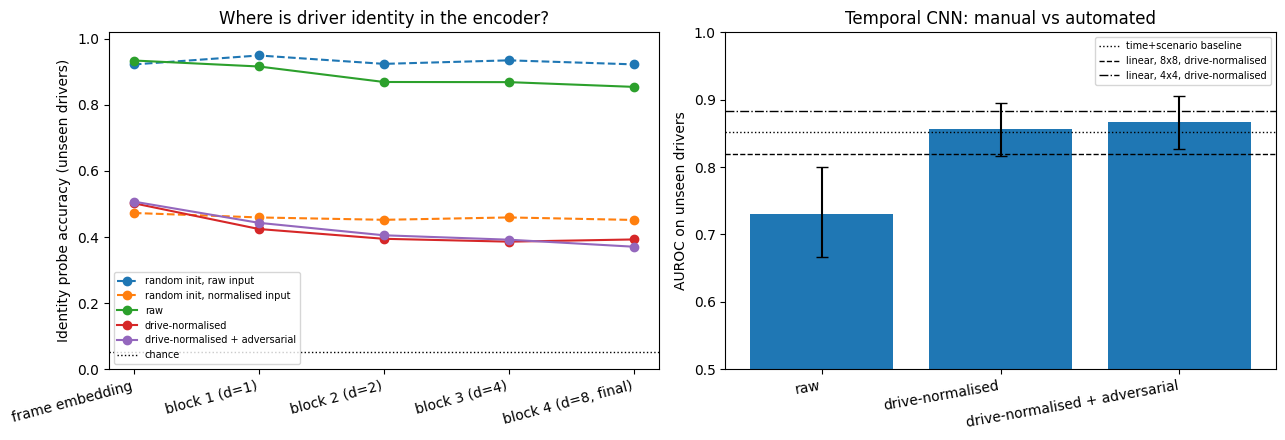

Done in 10.0 min


In [7]:
import os, io, re, json, time, copy, platform, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import torch, torch.nn as nn, torch.nn.functional as Fnn
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning); warnings.filterwarnings("ignore", category=UserWarning)

OUT = Path("/kaggle/working/mand"); CACHE, RES, FIG = OUT / "cache", OUT / "results", OUT / "figures"
norm = lambda s: re.sub(r"[^a-z]", "", str(s).lower())
WIN, SCALE, LAM, EPOCHS, BS, SEEDS = 80, 50.0, 1.0, 25, 128, [0, 1, 2]
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu"); NCPU = os.cpu_count(); torch.set_num_threads(NCPU)
W = pd.read_parquet(RES / "windows.parquet")
M = pd.read_csv(OUT / "manifest.csv"); M = M[M.status == "ok"]
t_start = time.time(); print("Device:", dev, "| CPU:", platform.processor() or platform.machine(), "| threads:", NCPU)

# 1. Window tensors: 8x8 pooled seat + backrest per frame (128 values), same windows as Cell 4
def pool8(m): return m.reshape(len(m), 8, 4, 8, 4).mean((2, 4)).reshape(len(m), 64)
Xw = np.zeros((len(W), WIN, 128), np.float32); T0 = []; i = 0
for pid, grp in M.groupby("pid"):
    for scen in sorted(grp.scenario):
        z = np.load(CACHE / f"P{int(pid):02d}_{norm(scen)}.npz")
        bad = z["seat_blank"] | z["back_blank"]
        for k in ("seat_gap", "back_gap"):
            if k in z.files: bad = bad | z[k]
        valid, tt = ~bad, z["t"]
        fr = np.concatenate([pool8(z["seat"].astype(np.float32)), pool8(z["back"].astype(np.float32))], 1)
        for w in range(len(tt) // WIN):
            s = slice(w * WIN, (w + 1) * WIN); v = valid[s]
            if v.mean() < 0.9: continue
            seg = fr[s].copy(); seg[~v] = seg[v].mean(0); Xw[i] = seg; T0.append(float(tt[s][0])); i += 1
assert i == len(W) and np.allclose(T0, W.t0), "windows do not match Cell 4"
ref = (W.t0 < W.groupby("drive").t0.transform("min") + 60).to_numpy(); drv = W.drive.to_numpy()
Xn = Xw.copy()
for d in np.unique(drv):
    m = drv == d; Xn[m] -= Xw[m & ref].mean((0, 1))
E = np.where(~ref)[0]
INPUT = {"raw": Xw[E] / SCALE, "drive-normalised": Xn[E] / SCALE}; del Xw, Xn
labE, pidE, foldE = W.label.to_numpy()[E], W.pid.to_numpy()[E], W.fold.to_numpy()[E]
VARS = {"raw": ("raw", False), "drive-normalised": ("drive-normalised", False),
        "drive-normalised + adversarial": ("drive-normalised", True)}
print(f"Evaluation windows: {len(E)} | labelled: {(labE >= 0).sum()} | input shape per window: {INPUT['raw'].shape[1:]}")

# 2. Model, gradient reversal, training and inference
class TCN(nn.Module):
    def __init__(s, d_in=128, ch=64, dil=(1, 2, 4, 8)):
        super().__init__()
        s.emb = nn.Sequential(nn.Linear(d_in, ch), nn.ReLU())
        s.blocks = nn.ModuleList([nn.Sequential(nn.Conv1d(ch, ch, 3, padding=d, dilation=d), nn.BatchNorm1d(ch), nn.ReLU()) for d in dil])
        s.head = nn.Linear(ch, 1)
    def features(s, x):
        h = s.emb(x).transpose(1, 2); layers = [h.mean(2)]
        for b in s.blocks:
            h = h + b(h); layers.append(h.mean(2))
        return layers
    def forward(s, x):
        return s.head(s.features(x)[-1]).squeeze(1)

class GRL(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, lam): ctx.lam = lam; return x.view_as(x)
    @staticmethod
    def backward(ctx, g): return -ctx.lam * g, None

def train_model(Xa, ylab, ids, seed, adv):
    torch.manual_seed(seed); np.random.seed(seed)
    net = TCN().to(dev); idh = nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, int(ids.max()) + 1)).to(dev)
    opt = torch.optim.Adam(list(net.parameters()) + (list(idh.parameters()) if adv else []), lr=1e-3, weight_decay=1e-4)
    Xt, yt, it = torch.from_numpy(Xa), torch.from_numpy(ylab.astype(np.float32)), torch.from_numpy(ids.astype(np.int64))
    n = len(Xa); steps = EPOCHS * int(np.ceil(n / BS)); step = 0; g = torch.Generator().manual_seed(seed)
    for ep in range(EPOCHS):
        net.train(); idh.train(); perm = torch.randperm(n, generator=g)
        for b in range(0, n, BS):
            bi = perm[b:b + BS]; x, yb = Xt[bi].to(dev), yt[bi].to(dev)
            z = net.features(x)[-1]; logit = net.head(z).squeeze(1); m = yb >= 0
            loss = Fnn.binary_cross_entropy_with_logits(logit[m], yb[m]) if m.any() else logit.sum() * 0
            if adv:
                lam = LAM * (2 / (1 + np.exp(-10 * step / steps)) - 1)
                loss = loss + Fnn.cross_entropy(idh(GRL.apply(z, lam)), it[bi].to(dev))
            opt.zero_grad(); loss.backward(); opt.step(); step += 1
    return net.eval()

@torch.no_grad()
def predict(net, Xa, bs=512):
    net.eval(); return np.concatenate([torch.sigmoid(net(torch.from_numpy(Xa[b:b + bs]).to(dev))).cpu().numpy() for b in range(0, len(Xa), bs)])
@torch.no_grad()
def embed(net, Xa, bs=512):
    net.eval(); out = None
    for b in range(0, len(Xa), bs):
        L = [l.cpu().numpy() for l in net.features(torch.from_numpy(Xa[b:b + bs]).to(dev))]
        out = [[x] for x in L] if out is None else [o + [x] for o, x in zip(out, L)]
    return [np.concatenate(o) for o in out]
def id_probe(Z, y, fold):
    pred = np.zeros_like(y)
    for f in np.unique(fold):
        tr, te = fold != f, fold == f
        pred[te] = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000, tol=1e-3)).fit(Z[tr], y[tr]).predict(Z[te])
    return float((pred == y).mean())
def boot_auc(yl, q, g, B=1000, seed=0):
    rng = np.random.default_rng(seed); ug = np.unique(g); ix = {d: np.where(g == d)[0] for d in ug}; out = []
    for _ in range(B):
        ii = np.concatenate([ix[d] for d in rng.choice(ug, len(ug))])
        if len(np.unique(yl[ii])) == 2: out.append(roc_auc_score(yl[ii], q[ii]))
    return [float(v) for v in np.percentile(out, [2.5, 97.5])]

# 3. Task performance on unseen drivers (grouped 5-fold by driver, 3 seeds)
folds = list(GroupKFold(5).split(np.zeros(len(E)), groups=pidE)); lm = labE >= 0
TASK, keep = {}, {}
for vname, (inp, adv) in VARS.items():
    XE = INPUT[inp]; P = np.zeros((len(SEEDS), len(E)))
    for si, seed in enumerate(SEEDS):
        for k, (tr, te) in enumerate(folds):
            ids = np.unique(pidE[tr], return_inverse=True)[1]
            net = train_model(XE[tr], labE[tr], ids, seed, adv); P[si, te] = predict(net, XE[te])
            if vname == "drive-normalised" and seed == 0 and k == 0: keep = dict(net=copy.deepcopy(net).cpu().eval(), tr=tr, te=te)
        print(f"  {vname}: seed {seed} done | {(time.time() - t_start) / 60:.1f} min", flush=True)
    per_seed = [float(roc_auc_score(labE[lm], P[si, lm])) for si in range(len(SEEDS))]
    pm = P.mean(0); auc = float(roc_auc_score(labE[lm], pm[lm])); ci = boot_auc(labE[lm], pm[lm], pidE[lm])
    TASK[vname] = dict(auc_seed_avg=auc, ci=ci, per_seed=per_seed)
    print(f"TASK {vname:>31}: AUROC {auc:.3f} [{ci[0]:.3f}, {ci[1]:.3f}] | per seed {np.round(per_seed, 3).tolist()}")

# 4. Layer-wise identity probes: encoder trained on one half of the drivers, probed on the other half
LAYERS = ["frame embedding", "block 1 (d=1)", "block 2 (d=2)", "block 3 (d=4)", "block 4 (d=8, final)"]
pids = np.sort(np.unique(pidE)); halves = [pids[0::2], pids[1::2]]
chance_half = float(np.mean([1 / len(h) for h in halves]))
PROBE_VARS = {"random init, raw input": ("raw", None), "random init, normalised input": ("drive-normalised", None), **VARS}
PROBE = {}
for vname, (inp, adv) in PROBE_VARS.items():
    XE = INPUT[inp]; acc = np.zeros((2, len(LAYERS)))
    for h in range(2):
        prm, trm = np.isin(pidE, halves[h]), np.isin(pidE, halves[1 - h])
        if adv is None:
            torch.manual_seed(0); net = TCN().to(dev).eval()
        else:
            net = train_model(XE[trm], labE[trm], np.unique(pidE[trm], return_inverse=True)[1], 0, adv)
        acc[h] = [id_probe(Z, pidE[prm], foldE[prm]) for Z in embed(net, XE[prm])]
    PROBE[vname] = acc.mean(0).tolist()
    print(f"PROBE {vname:>31}: " + " | ".join(f"{l.split(' (')[0]} {a:.3f}" for l, a in zip(LAYERS, PROBE[vname])), flush=True)
print(f"Probe chance (about 1 in {int(round(1 / chance_half))}): {chance_half:.3f}")

# 5. E5: INT8 quantisation of the drive-normalised model (fold 0, seed 0), CPU single-thread latency
torch.backends.quantized.engine = "x86" if "x86" in torch.backends.quantized.supported_engines else "fbgemm"
from torch.ao.quantization import get_default_qconfig_mapping
from torch.ao.quantization.quantize_fx import prepare_fx, convert_fx
fp = keep["net"]; XEn = INPUT["drive-normalised"]; calib = XEn[keep["tr"][:512]]; ex = (torch.from_numpy(calib[:1]),)
try:
    prep = prepare_fx(copy.deepcopy(fp), get_default_qconfig_mapping(torch.backends.quantized.engine), ex)
    with torch.no_grad():
        for b in range(0, len(calib), 64): prep(torch.from_numpy(calib[b:b + 64]))
    qnet = convert_fx(prep); qtype = "static INT8 (FX graph mode)"
    with torch.no_grad(): qnet(ex[0])
except Exception as e:
    print(f"FX static quantisation failed ({type(e).__name__}: {str(e)[:150]}); falling back to dynamic INT8 on Linear layers")
    qnet = torch.ao.quantization.quantize_dynamic(copy.deepcopy(fp), {nn.Linear}, dtype=torch.qint8); qtype = "dynamic INT8 (Linear layers only)"
@torch.no_grad()
def cpu_predict(m, Xa, bs=256): return np.concatenate([torch.sigmoid(m(torch.from_numpy(Xa[b:b + bs]))).numpy() for b in range(0, len(Xa), bs)])
def size_kb(m):
    buf = io.BytesIO(); torch.save(m.state_dict(), buf); return buf.tell() / 1024
def latency_ms(m, x, n=1000):
    with torch.no_grad():
        for _ in range(50): m(x)
        ts = []
        for _ in range(n):
            t = time.perf_counter(); m(x); ts.append(time.perf_counter() - t)
    return float(np.median(ts) * 1e3)
te = keep["te"]; Xte, yte = XEn[te], labE[te]; mt = yte >= 0
torch.set_num_threads(1); x1 = torch.from_numpy(Xte[:1])
E5 = dict(quantisation=qtype, params=int(sum(p.numel() for p in fp.parameters())),
          fp32=dict(auc=float(roc_auc_score(yte[mt], cpu_predict(fp, Xte)[mt])), size_kb=size_kb(fp), latency_ms=latency_ms(fp, x1)),
          int8=dict(auc=float(roc_auc_score(yte[mt], cpu_predict(qnet, Xte)[mt])), size_kb=size_kb(qnet), latency_ms=latency_ms(qnet, x1)))
torch.set_num_threads(NCPU)
print(f"\nE5 ({qtype}, {E5['params']:,} parameters, fold-0 unseen drivers, 1 CPU thread):")
for k in ("fp32", "int8"):
    print(f"  {k}: AUROC {E5[k]['auc']:.4f} | size {E5[k]['size_kb']:.0f} KB | median latency per 10 s window {E5[k]['latency_ms']:.3f} ms")
print(f"  AUROC change {E5['int8']['auc'] - E5['fp32']['auc']:+.4f} | speed-up x{E5['fp32']['latency_ms'] / E5['int8']['latency_ms']:.2f} "
      f"| size x{E5['fp32']['size_kb'] / E5['int8']['size_kb']:.2f} smaller")

# 6. Figure and saved results
e4 = json.load(open(RES / "e4.json"))["E4"]; base = json.load(open(RES / "e3.json"))["time+scenario only (HGB)"]["lodo_auc"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for vname, accs in PROBE.items():
    ax[0].plot(range(len(LAYERS)), accs, "o--" if "random" in vname else "o-", label=vname)
ax[0].axhline(chance_half, ls=":", c="k", lw=1, label="chance"); ax[0].set_ylim(0, 1.02)
ax[0].set_xticks(range(len(LAYERS))); ax[0].set_xticklabels(LAYERS, rotation=15, ha="right")
ax[0].set_ylabel("Identity probe accuracy (unseen drivers)"); ax[0].set_title("Where is driver identity in the encoder?"); ax[0].legend(fontsize=7)
names = list(TASK); xi = np.arange(len(names)); a_ = [TASK[n]["auc_seed_avg"] for n in names]
ax[1].bar(xi, a_, yerr=[[a - TASK[n]["ci"][0] for n, a in zip(names, a_)], [TASK[n]["ci"][1] - a for n, a in zip(names, a_)]], capsize=4, color="tab:blue")
for val, ls, lab in [(base, ":", "time+scenario baseline"), (e4["8x8 | drive-normalised"]["lodo_auc"], "--", "linear, 8x8, drive-normalised"),
                     (e4["4x4 | drive-normalised"]["lodo_auc"], "-.", "linear, 4x4, drive-normalised")]:
    ax[1].axhline(val, ls=ls, c="k", lw=1, label=lab)
ax[1].set_xticks(xi); ax[1].set_xticklabels(names, rotation=10, ha="right"); ax[1].set_ylim(0.5, 1.0)
ax[1].set_ylabel("AUROC on unseen drivers"); ax[1].set_title("Temporal CNN: manual vs automated"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "e3e5_neural.png", dpi=200); plt.show()
json.dump(dict(TASK=TASK, PROBE=PROBE, probe_layers=LAYERS, probe_chance=chance_half, E5=E5), open(RES / "neural.json", "w"), indent=2)
print(f"Done in {(time.time() - t_start) / 60:.1f} min")